# Text Generation with Markov Chains: fluent, or original, but not both

**The question:** a **Markov chain** writes text by looking at the last few words and picking a next word that followed them somewhere in its training book. It is the simplest language model there is, and with a long memory it produces surprisingly fluent sentences. But is it *writing*, or *quoting*? *How does the length of the memory trade fluency against originality, how much text does a chain need, and how does it compare with a neural language model?*

**How this notebook works.** Each section starts with a plain-English explanation, then the code, then a "how to read this" note.

1. The analogy
2. Setup
3. Audit the book
4. Hypotheses and why we chose each test
5. A Markov chain from scratch
6. H1: does a longer memory mean more copying?
7. H2: does a longer memory mean more fluent text?
8. H3: does more text mean less copying?
9. H4: how does a neural language model compare?
10. Takeaways
11. Limitations

**Run it:** `uv run jupyter lab NLP/text-generation/text_generation.ipynb`, or *Run All* in any Jupyter. The book (about 770 KB, Project Gutenberg, public domain) and two small language models (GPT-2 and DistilGPT-2, from the Hugging Face hub) download themselves on the first run. It takes about 3 minutes with a GPU.

## 1. 💡 The simple analogy

Imagine writing a sentence by **cutting up a novel and gluing together snippets**, like a ransom note.

- You start with the first word of a real sentence. To pick the next word you look at **only the last word or two you wrote** and find a place in the book where those same words appeared. Then you take whatever word came next *there*.
- If you only look at the **last one word** ("memory of 1"), almost any word could come next, so the result is nonsense that is *entirely new*.
- If you look at the **last four words** ("memory of 4"), there is usually only **one** place in the book where those four words occurred, so you are forced to copy the sentence that was already there. The result sounds perfect, because it **is** the book.
- A **neural language model** is a different kind of writer: it has learned patterns from billions of words, so it can write new sentences that were never in any book.

## 2. Setup

*What:* imports and named constants. *Why:* one place for numbers like the seed, the number of generated sentences per source and the memory lengths to try keeps the notebook reproducible and avoids "magic numbers".

In [1]:
import os
import re
import urllib.request
import warnings
from collections import defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from scipy import stats

os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
warnings.filterwarnings("ignore", message="IProgress not found")
from huggingface_hub.utils import logging as hub_logging  # noqa: E402
from transformers import AutoModelForCausalLM, AutoTokenizer, pipeline, set_seed  # noqa: E402
from transformers.utils import logging as hf_logging  # noqa: E402

hub_logging.set_verbosity_error()
hf_logging.set_verbosity_error()
hf_logging.disable_progress_bar()

DATA_DIR = Path("data")
OUT_DIR = Path("outputs")
BOOK_URL = "https://www.gutenberg.org/cache/epub/1342/pg1342.txt"  # Pride and Prejudice
SEED = 365
N_SENTENCES = 200  # generated sentences per source
N_BOOTSTRAP = 2_000
ORDERS = [1, 2, 3, 4]
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
TEAL, ORANGE, NAVY, GREY, PURPLE = "#2a9d8f", "#e76f51", "#264653", "#b8bcc2", "#7b5ea7"

sns.set_theme(style="whitegrid", context="notebook")
OUT_DIR.mkdir(exist_ok=True)
DATA_DIR.mkdir(exist_ok=True)
rng = np.random.default_rng(SEED)


def fmt_p(p: float) -> str:
    """Formats a p-value, showing values below floating-point precision honestly.

    Args:
        p: The p-value.

    Returns:
        A short string such as ``3.2e-08`` or ``< 1e-300``.
    """
    return "< 1e-300" if float(p) < 1e-300 else f"{float(p):.1e}"

## 3. Audit the book

*What:* download Jane Austen's *Pride and Prejudice* (public domain), strip the licence text and chapter headings, and cut it into sentences. We keep the **first 90% of the sentences to train on** and hold back the **last 10%** as examples of real, unseen text. *Why:* we need a corpus anyone can download, and a set of real sentences the chain has never seen to compare with.

> **Problems in the legacy script this replaces:** it trained on a private text file (`data/data.txt`) that no one else could obtain, with the `markovify` library at a memory of **4** words, then printed five sentences. It had no evaluation at all, no seed, a part-of-speech class that was defined but never used, and it did not notice that a four-word memory mostly **quotes** its training text.

In [2]:
def load_book() -> list[str]:
    """Downloads Pride and Prejudice (public domain, once) and splits it into sentences.

    Returns:
        The sentences in reading order, each a single line of text.

    Raises:
        ValueError: If the book text cannot be found in the download.
    """
    path = DATA_DIR / "pride_and_prejudice.txt"
    if not path.exists():
        urllib.request.urlretrieve(BOOK_URL, path)
    raw = path.read_text(encoding="utf-8-sig")
    start = re.search(r"\*\*\* START OF .*? \*\*\*", raw)
    end = re.search(r"\*\*\* END OF .*? \*\*\*", raw)
    if not start or not end:
        raise ValueError("Could not find the book text in the Project Gutenberg file")
    body = raw[start.end() : end.start()]
    body = re.sub(r"(?m)^\s*(CHAPTER|Chapter) [IVXLC\d]+.*$", " ", body)  # chapter headings
    body = re.sub(r"\[Illustration[^\]]*\]", " ", body)
    body = re.sub(r"[_*]", "", body).replace("“", '"').replace("”", '"')
    body = body.replace("’", "'").replace("‘", "'")
    paragraphs = [re.sub(r"\s+", " ", p).strip() for p in re.split(r"\n\s*\n", body)]
    text = " ".join(p for p in paragraphs if p)
    sentences = re.split(r'(?<=[.!?])["\']?\s+(?=["A-Z])', text)
    return [s.strip() for s in sentences if len(s.split()) >= 3]


sentences = load_book()
cut = int(0.9 * len(sentences))
train_sentences, held_sentences = sentences[:cut], sentences[cut:]
train_text = " ".join(train_sentences)
words = re.findall(r"[a-z']+", train_text.lower())
counts = pd.Series(words).value_counts()
print(
    f"{len(sentences):,} sentences; {len(train_sentences):,} for training (the first 90% of "
    f"the book) and {len(held_sentences):,} held back (the last 10%)"
)
print(
    f"Training text: {len(words):,} words, {len(counts):,} different words; "
    f"{(counts == 1).mean():.0%} of the different words occur only once"
)
lengths = pd.Series([len(s.split()) for s in train_sentences])
print(
    f"Sentence length: median {lengths.median():.0f} words, 90th percentile "
    f"{lengths.quantile(0.9):.0f}, longest {lengths.max()}"
)
print(f"The 8 commonest words: {', '.join(counts.index[:8])}")

6,467 sentences; 5,820 for training (the first 90% of the book) and 647 held back (the last 10%)
Training text: 115,381 words, 6,630 different words; 40% of the different words occur only once
Sentence length: median 15 words, 90th percentile 40, longest 389
The 8 commonest words: the, to, of, and, her, a, i, in


**How to read this:**

- **6,467 sentences:** **5,820 for training** (the first 90% of the book) and **647 held back** (the last 10%).
- **The training text has 115,381 words** and **6,630 different words**; **40% of the different words occur only once**. Many words are rare, which is why a chain with a long memory so often has only one way to continue.
- **Sentences are long:** median **15 words**, 90th percentile **40**, the longest **389** (Austen's long, semi-colon-chained sentences). The commonest words are "the", "to", "of", "and", "her", "a", "i" and "in".

## 4. Hypotheses and why we chose each test

| # | Question | H₀ (nothing interesting) | Hₐ | Test |
|---|---|---|---|---|
| H1 | Does a longer memory mean more copying from the book? | Copying is the same for every memory length | Copying rises with the memory | Share of eight-word runs copied word for word, with bootstrap CIs; Spearman correlation with the memory length |
| H2 | Does a longer memory mean more fluent text? | Fluency is the same | More fluent | GPT-2's perplexity of each sentence; Kruskal-Wallis and Cliff's δ against real sentences |
| H3 | Does more training text mean less copying? | Copying is the same for any amount of text | Falls with more text | Copying at 10%, 25%, 50% and 100% of the book |
| H4 | Does a neural model beat the chain on both counts? | Same fluency | Neural is more fluent | Mann-Whitney U and Cliff's δ |

*Why these measures?* We need two numbers for any piece of generated text: **how original is it** (share of its eight-word runs that appear word for word in the training text, because with a memory of *k* words, every run of *k+1* words is a copy by construction, so we look at longer runs), and **how fluent is it** (the **perplexity** under a separate, larger language model, GPT-2: low means the text reads like normal English; this is an independent judge, not the chain grading itself). Perplexity is skewed, so we use rank-based tests and medians.

## 5. A Markov chain from scratch

*What:* about 30 lines of code. For every run of *k* words (the "state") in the training sentences, the chain remembers the list of words that followed it. To write a sentence it starts at the beginning of a sentence, repeatedly looks up the last *k* words, picks one of the words that followed, and stops when the book's sentence would have ended. *Why from scratch?* It shows there is no magic: the chain is a lookup table, with the `markovify` library of the legacy script doing the same.

In [3]:
class MarkovChain:
    """A word-level Markov chain: the next word depends only on the last ``order`` words.

    Args:
        order: How many previous words the chain remembers (its "state size").
    """

    BEGIN = "<begin>"

    def __init__(self, order: int) -> None:
        self.order = order
        self.table: dict[tuple, list[str]] = defaultdict(list)

    def fit(self, texts: list[str]) -> "MarkovChain":
        """Learns, for every run of ``order`` words, the words that followed it.

        Args:
            texts: Training sentences.

        Returns:
            The fitted chain.
        """
        for sentence in texts:
            tokens = [self.BEGIN] * self.order + sentence.split() + [None]
            for i in range(len(tokens) - self.order):
                self.table[tuple(tokens[i : i + self.order])].append(tokens[i + self.order])
        return self

    def sample(self, gen: np.random.Generator, max_words: int = 60) -> str | None:
        """Walks the chain from the start of a sentence to its end.

        Args:
            gen: Random number generator.
            max_words: Give up (return None) if the sentence runs longer than this.

        Returns:
            The generated sentence, or None if it was too long.
        """
        state = (self.BEGIN,) * self.order
        out: list[str] = []
        while len(out) <= max_words:
            options = self.table[state]
            nxt = options[gen.integers(len(options))]
            if nxt is None:
                return " ".join(out)
            out.append(nxt)
            state = state[1:] + (nxt,)
        return None


def clean_words(sentence: str) -> list[str]:
    """Lower-case words of a sentence, without punctuation."""
    return re.findall(r"[a-z']+", sentence.lower())


def ngrams(tokens: list[str], n: int = 8) -> list[tuple]:
    """All runs of ``n`` consecutive words."""
    return [tuple(tokens[i : i + n]) for i in range(len(tokens) - n + 1)]


def train_ngram_set(texts: list[str], n: int = 8) -> set:
    """Every ``n``-word run that occurs in the training sentences."""
    return {g for s in texts for g in ngrams(clean_words(s), n)}


def copy_share(sentence: str, known: set, n: int = 8) -> float:
    """Share of a sentence's ``n``-word runs that appear word for word in the training text.

    Args:
        sentence: The sentence to check.
        known: The training text's ``n``-word runs.
        n: Run length.

    Returns:
        A number from 0 (all new) to 1 (all copied), or NaN if the sentence is too short.
    """
    grams = ngrams(clean_words(sentence), n)
    return float(np.mean([g in known for g in grams])) if grams else float("nan")


def generate(chain: MarkovChain, n: int, seed: int, min_words: int = 6) -> tuple[list[str], int]:
    """Draws ``n`` sentences of at least ``min_words`` words from a chain.

    Args:
        chain: A fitted chain.
        n: Number of sentences wanted.
        seed: Seed for the random draws.
        min_words: Shorter sentences are thrown away and redrawn.

    Returns:
        The sentences and the number of attempts it took.
    """
    gen = np.random.default_rng(seed)
    out, attempts = [], 0
    while len(out) < n and attempts < 50 * n:
        attempts += 1
        s = chain.sample(gen)
        if s and len(s.split()) >= min_words:
            out.append(s)
    return out, attempts


known = train_ngram_set(train_sentences)
chains = {k: MarkovChain(k).fit(train_sentences) for k in ORDERS}
samples, attempts = {}, {}
for k, chain in chains.items():
    samples[k], attempts[k] = generate(chain, N_SENTENCES, SEED + k)
    print(f"Order {k}: {len(chain.table):,} remembered states; example: {samples[k][0][:140]!r}")

Order 1: 12,763 remembered states; example: '"But she eagerly she is at last evening engagements.'
Order 2: 59,119 remembered states; example: 'They then sat still five minutes seemed to have been totally unsuspicious of her own.'
Order 3: 95,125 remembered states; example: 'My dear Lizzy, they must have passed within ten miles of us.'
Order 4: 104,594 remembered states; example: 'Oh, he is the handsomest young man that ever was seen!'


**How to read this:**

- **The memory grows fast:** the chain remembers **12,763** different states with a memory of 1 word, **59,119** with 2, **95,125** with 3 and **104,594** with 4. With four words of memory almost every state has been seen **once**.
- **The examples already show the story:** order 1 gives word salad ("But she eagerly she is at last evening engagements."), order 2 something half-grammatical, and orders 3 and 4 read as real Austen ("Oh, he is the handsomest young man that ever was seen!"), because they quote it.

## 6. H1: does a longer memory mean more copying?

*What:* 200 sentences from each chain (memory 1, 2, 3 and 4), and for each sentence the **share of its eight-word runs that occur word for word in the training text**. We report the average with a bootstrap 95% interval, the share of sentences that are **mostly copied** (over half their runs) and the share that are **an exact sentence from the book**. As a reference, the same measure on 200 real sentences from the *held-out* end of the book. *Why:* a real, new sentence almost never shares an eight-word run with other text.

In [4]:
held_sample = [s for s in held_sentences if len(s.split()) >= 6]
held_sample = [held_sample[i] for i in rng.choice(len(held_sample), N_SENTENCES, replace=False)]
train_sentence_set = set(train_sentences)
rows = []
for k in ORDERS:
    shares = np.array([copy_share(s, known) for s in samples[k]])
    shares = shares[~np.isnan(shares)]
    verbatim = np.mean([s in train_sentence_set for s in samples[k]])
    boot = [rng.choice(shares, len(shares)).mean() for _ in range(N_BOOTSTRAP)]
    low, high = np.percentile(boot, [2.5, 97.5])
    rows.append(
        {
            "source": f"Markov order {k}",
            "mean copied 8-grams": shares.mean(),
            "ci_low": low,
            "ci_high": high,
            "mostly copied (over half)": float((shares > 0.5).mean()),
            "whole sentence copied": float(verbatim),
            "attempts per sentence": attempts[k] / N_SENTENCES,
        }
    )
held_shares = np.array([copy_share(s, known) for s in held_sample])
held_shares = held_shares[~np.isnan(held_shares)]
rows.append(
    {
        "source": "real held-out sentences",
        "mean copied 8-grams": held_shares.mean(),
        "ci_low": np.nan,
        "ci_high": np.nan,
        "mostly copied (over half)": float((held_shares > 0.5).mean()),
        "whole sentence copied": 0.0,
        "attempts per sentence": np.nan,
    }
)
copy_table = pd.DataFrame(rows).set_index("source")
print(
    "How much of each generated sentence is copied word for word from the training text "
    "(runs of eight words):"
)
print(copy_table.round(3).to_string())
orders_arr = np.repeat(ORDERS, [len(samples[k]) for k in ORDERS])
all_shares = np.concatenate([[copy_share(s, known) for s in samples[k]] for k in ORDERS])
rho = stats.spearmanr(orders_arr, all_shares, nan_policy="omit")
print(
    f"\nSpearman correlation between the order and the copied share: {rho.statistic:+.2f}, "
    f"p = {fmt_p(rho.pvalue)}"
)

How much of each generated sentence is copied word for word from the training text (runs of eight words):
                         mean copied 8-grams  ci_low  ci_high  mostly copied (over half)  whole sentence copied  attempts per sentence
source                                                                                                                                
Markov order 1                         0.000   0.000    0.000                      0.000                  0.000                  1.195
Markov order 2                         0.071   0.051    0.093                      0.023                  0.010                  1.190
Markov order 3                         0.681   0.636    0.727                      0.740                  0.335                  1.155
Markov order 4                         0.955   0.936    0.971                      0.983                  0.785                  1.155
real held-out sentences                0.000     NaN      NaN                      0


Spearman correlation between the order and the copied share: +0.87, p = 1.4e-221


**How to read this:**

- **Copying climbs steeply with the memory:** the share of copied eight-word runs is **0.0%** at order 1, **7.1%** (95% CI 5.1% to 9.3%) at order 2, **68.1%** (63.6% to 72.7%) at order 3 and **95.5%** (93.6% to 97.1%) at order 4. The Spearman correlation between memory and copying is **+0.87** (p ≈ 1e-221). **We reject H₀.**
- **At order 4 the chain is almost a photocopier:** **98.3%** of its sentences are more than half copied, and **78.5%** are *exact* sentences from the book. At order 3 it is **33.5%**; at order 2 **1.0%**.
- **Real unseen sentences score 0.0%**, as they should: genuinely new text does not repeat the training text. Orders 1 and 2 are the only chains in the same range.
- Each draw needed about 1.2 attempts per sentence, so the chain rarely gets stuck.

## 7. H2: does a longer memory mean more fluent text?

*What:* we ask **GPT-2** (a separate, bigger language model) how surprised it is by each sentence, its **perplexity**: low means the text reads like normal English, high means it is odd. We compare the 200 sentences of each chain with the 200 real held-out sentences, using the median perplexity with a bootstrap interval, **Cliff's δ** against the real sentences (0 means equally fluent, positive means worse), and a **Kruskal-Wallis** test across the four chains. *Why an outside judge?* If the chain graded itself, copying would look perfect.

In [5]:
judge_name = "gpt2"
tok = AutoTokenizer.from_pretrained(judge_name)
judge = AutoModelForCausalLM.from_pretrained(judge_name).to(DEVICE).eval()


@torch.no_grad()
def sentence_perplexity(texts: list[str], batch: int = 32) -> np.ndarray:
    """How surprised a language model (GPT-2) is by each sentence: lower means more fluent.

    Args:
        texts: Sentences to score.
        batch: Batch size.

    Returns:
        One perplexity per sentence (the exponential of the average per-token loss).
    """
    out = []
    for start in range(0, len(texts), batch):
        chunk = [tok.bos_token + t for t in texts[start : start + batch]]
        enc = tok(chunk, return_tensors="pt", padding=True, truncation=True, max_length=96)
        enc = {k: v.to(DEVICE) for k, v in enc.items()}
        logits = judge(**enc).logits[:, :-1]
        target = enc["input_ids"][:, 1:]
        mask = enc["attention_mask"][:, 1:].float()
        loss = (
            torch.nn.functional.cross_entropy(logits.transpose(1, 2), target, reduction="none")
            * mask
        )
        out.append((loss.sum(1) / mask.sum(1)).exp().cpu().numpy())
    return np.concatenate(out)


tok.pad_token = tok.eos_token
tok.padding_side = "right"
ppl = {f"Markov order {k}": sentence_perplexity(samples[k]) for k in ORDERS}
ppl["real held-out sentences"] = sentence_perplexity(held_sample)
rows = []
for name, values in ppl.items():
    boot = [np.median(rng.choice(values, len(values))) for _ in range(N_BOOTSTRAP)]
    low, high = np.percentile(boot, [2.5, 97.5])
    real = ppl["real held-out sentences"]
    delta = 2 * stats.mannwhitneyu(values, real).statistic / (len(values) * len(real)) - 1
    rows.append(
        {
            "source": name,
            "median perplexity": np.median(values),
            "ci_low": low,
            "ci_high": high,
            "cliffs_delta_vs_real": delta,
        }
    )
ppl_table = pd.DataFrame(rows).set_index("source")
print("Perplexity under GPT-2 (lower = reads more like fluent English):")
print(ppl_table.round(2).to_string())
kw = stats.kruskal(*[ppl[f"Markov order {k}"] for k in ORDERS])
print(
    f"\nKruskal-Wallis across the four Markov orders: H = {kw.statistic:.0f}, "
    f"p = {fmt_p(kw.pvalue)}"
)

Perplexity under GPT-2 (lower = reads more like fluent English):
                         median perplexity  ci_low  ci_high  cliffs_delta_vs_real
source                                                                           
Markov order 1                  357.049988  327.30   392.74                  0.90
Markov order 2                  174.990005  160.58   194.20                  0.63
Markov order 3                  107.669998   97.52   120.49                  0.24
Markov order 4                   76.669998   72.09    88.61                  0.01
real held-out sentences          78.040001   69.55    84.50                  0.00

Kruskal-Wallis across the four Markov orders: H = 373, p = < 1e-300


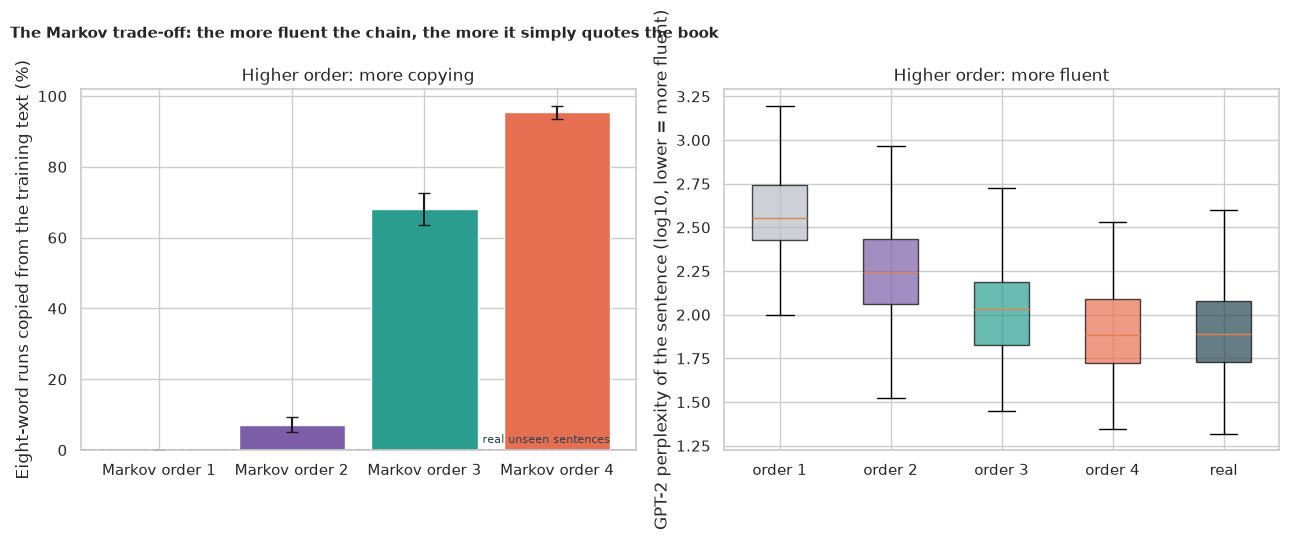

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
order_names = [f"Markov order {k}" for k in ORDERS]
colors4 = [GREY, PURPLE, TEAL, ORANGE]
axes[0].bar(
    order_names,
    [copy_table.loc[n, "mean copied 8-grams"] * 100 for n in order_names],
    color=colors4,
    yerr=[
        [
            (copy_table.loc[n, "mean copied 8-grams"] - copy_table.loc[n, "ci_low"]) * 100
            for n in order_names
        ],
        [
            (copy_table.loc[n, "ci_high"] - copy_table.loc[n, "mean copied 8-grams"]) * 100
            for n in order_names
        ],
    ],
    capsize=4,
)
axes[0].axhline(
    copy_table.loc["real held-out sentences", "mean copied 8-grams"] * 100,
    color=NAVY,
    ls="--",
    lw=1.2,
)
axes[0].text(
    3.4,
    copy_table.loc["real held-out sentences", "mean copied 8-grams"] * 100 + 2,
    "real unseen sentences",
    color=NAVY,
    ha="right",
    fontsize=8,
)
axes[0].set_ylabel("Eight-word runs copied from the training text (%)")
axes[0].set_title("Higher order: more copying")
data_box = [np.log10(ppl[n]) for n in order_names] + [np.log10(ppl["real held-out sentences"])]
bp = axes[1].boxplot(
    data_box,
    tick_labels=[f"order {k}" for k in ORDERS] + ["real"],
    patch_artist=True,
    showfliers=False,
)
for patch, c in zip(bp["boxes"], colors4 + [NAVY], strict=True):
    patch.set_facecolor(c)
    patch.set_alpha(0.7)
axes[1].set_ylabel("GPT-2 perplexity of the sentence (log10, lower = more fluent)")
axes[1].set_title("Higher order: more fluent")
fig.suptitle(
    "The Markov trade-off: the more fluent the chain, the more it simply quotes the book",
    x=0.01,
    ha="left",
    fontweight="bold",
    fontsize=11,
)
fig.tight_layout()
fig.savefig(OUT_DIR / "01_copying_vs_fluency.png", dpi=150)
plt.show()

**How to read this:**

- **A longer memory reads better:** the median perplexity is **357** at order 1, **175** at order 2, **108** at order 3 and **76.7** at order 4. The real sentences score **78.0**. Kruskal-Wallis across the four chains gives H = 373, p ≈ 0. **We reject H₀.**
- **Order 4 is indistinguishable from the real thing** (Cliff's δ = **0.01**), order 3 is slightly worse (δ = 0.24), order 2 clearly worse (δ = 0.63) and order 1 nearly always worse (δ = 0.90).
- **Put the two results together:** the chains that read like real English (orders 3 and 4) are the ones that copy the book, and the one that is wholly original (order 1) is gibberish. *Fluency and originality pull in opposite directions for a Markov chain.* The figure shows both sides of the trade.
- A caution: GPT-2 has probably read *Pride and Prejudice* during its training, so it is even less surprised by quoted passages. That strengthens, not weakens, the point that fluent chains are quoting.

## 8. H3: does more text mean less copying?

*What:* the order-2 and order-3 chains trained on 10%, 25%, 50% and 100% of the training sentences. For each, 200 sentences, and the share of their eight-word runs that appear in *that* training text. *Why:* with more text, each state has been followed by more different words, so the chain has more ways to continue and does not need to repeat.

In [7]:
FRACTIONS = [0.1, 0.25, 0.5, 1.0]
size_rows = []
for k in (2, 3):
    for frac in FRACTIONS:
        sub = train_sentences[: int(frac * len(train_sentences))]
        known_sub = train_ngram_set(sub)
        chain = MarkovChain(k).fit(sub)
        out, att = generate(chain, N_SENTENCES, SEED + 100 * k)
        shares = np.array([copy_share(s, known_sub) for s in out])
        size_rows.append(
            {
                "order": k,
                "share of the book": frac,
                "words": int(sum(len(s.split()) for s in sub)),
                "copied 8-grams": np.nanmean(shares),
                "attempts per sentence": att / N_SENTENCES,
            }
        )
size = pd.DataFrame(size_rows)
print(size.round(3).to_string(index=False))

 order  share of the book  words  copied 8-grams  attempts per sentence
     2               0.10  12263           0.326                  1.170
     2               0.25  28288           0.188                  1.150
     2               0.50  57207           0.125                  1.185
     2               1.00 114876           0.052                  1.165
     3               0.10  12263           0.915                  1.190
     3               0.25  28288           0.846                  1.210
     3               0.50  57207           0.752                  1.195
     3               1.00 114876           0.671                  1.135


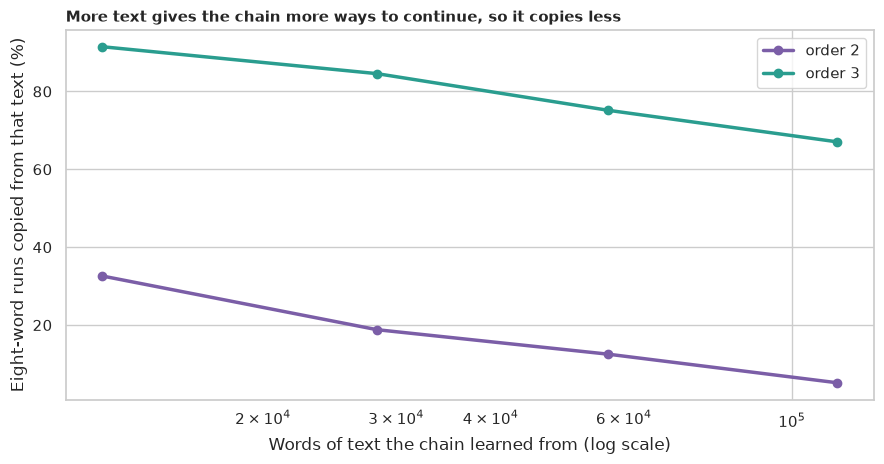

In [8]:
fig, ax = plt.subplots(figsize=(9, 4.8))
for k, color in zip((2, 3), (PURPLE, TEAL), strict=True):
    sub = size[size["order"] == k]
    ax.plot(
        sub["words"],
        sub["copied 8-grams"] * 100,
        marker="o",
        lw=2.5,
        color=color,
        label=f"order {k}",
    )
ax.set_xscale("log")
ax.set_xlabel("Words of text the chain learned from (log scale)")
ax.set_ylabel("Eight-word runs copied from that text (%)")
ax.set_title(
    "More text gives the chain more ways to continue, so it copies less",
    loc="left",
    fontweight="bold",
    fontsize=11,
)
ax.legend()
fig.tight_layout()
fig.savefig(OUT_DIR / "02_corpus_size.png", dpi=150)
plt.show()

**How to read this:**

- **More text means less copying, in both chains:** at order 2 the copied share falls from **32.6%** (12,263 words of training text) to **18.8%**, **12.5%** and **5.2%** (114,876 words). At order 3 it falls from **91.5%** to **84.6%**, **75.2%** and **67.1%**.
- **But the fall is slow:** multiplying the text by nearly ten only cuts the order-3 copying by about a quarter. To make a chain of memory 3 mostly original, you would need far more than one novel, which is how real n-gram language models ended up trained on billions of words.
- **There is no free lunch:** a chain with a short memory is original at any size, and a chain with a long memory is only original if it has an enormous amount of text.

## 9. H4: how does a neural language model compare?

*What:* we let **DistilGPT-2** (a small neural language model, not fine-tuned on the book) write 200 sentences from the one-word prompt "The" and score them in the same two ways: perplexity under GPT-2 and the share of eight-word runs copied from the book. We compare its perplexity with the order-3 chain (the best chain that is not almost entirely quotation) using a Mann-Whitney test and Cliff's δ. *Why:* the question is whether a model can be fluent **and** original at the same time.

In [9]:
set_seed(SEED)
writer = pipeline("text-generation", model="distilgpt2", device=0 if DEVICE == "cuda" else -1)
raw = writer(
    ["The"] * N_SENTENCES,
    max_new_tokens=40,
    do_sample=True,
    top_k=50,
    pad_token_id=50256,
    truncation=True,
)
neural = []
for item in raw:
    text = re.sub(r"\s+", " ", item[0]["generated_text"]).strip()
    first = re.split(r'(?<=[.!?])["\']?\s+', text)[0]
    neural.append(first if len(first.split()) >= 6 else text)
print(f"Example from DistilGPT-2: {neural[0][:160]!r}")
neural_ppl = sentence_perplexity(neural)
neural_copy = np.array([copy_share(s, known) for s in neural])
neural_copy = neural_copy[~np.isnan(neural_copy)]
vocab_train = set(words)
oov = np.mean([w not in vocab_train for s in neural for w in clean_words(s)])
rows = []
for name, values, shares in [
    (
        "Markov order 3",
        ppl["Markov order 3"],
        copy_table.loc["Markov order 3", "mean copied 8-grams"],
    ),
    (
        "Markov order 4",
        ppl["Markov order 4"],
        copy_table.loc["Markov order 4", "mean copied 8-grams"],
    ),
    ("DistilGPT-2 (no fine-tuning)", neural_ppl, neural_copy.mean()),
    (
        "real held-out sentences",
        ppl["real held-out sentences"],
        copy_table.loc["real held-out sentences", "mean copied 8-grams"],
    ),
]:
    rows.append(
        {"source": name, "median perplexity": np.median(values), "mean copied 8-grams": shares}
    )
compare = pd.DataFrame(rows).set_index("source")
print(compare.round(3).to_string())
print(f"\nShare of DistilGPT-2's words that never occur in the book: {oov:.1%}")
mw = stats.mannwhitneyu(neural_ppl, ppl["Markov order 3"])
d = 2 * mw.statistic / (len(neural_ppl) * len(ppl["Markov order 3"])) - 1
print(
    f"DistilGPT-2 vs Markov order 3 perplexity: Mann-Whitney p = {fmt_p(mw.pvalue)}, "
    f"Cliff's delta = {d:+.2f} (negative: the neural text is more fluent)"
)

Example from DistilGPT-2: "The A.L.S.'s “a “hateful” video is showing a white man in a white SUV walking down a street next to a Confederate flag."


                              median perplexity  mean copied 8-grams
source                                                              
Markov order 3                       107.669998                0.681
Markov order 4                        76.668999                0.955
DistilGPT-2 (no fine-tuning)          32.636002                0.000
real held-out sentences               78.040001                0.000

Share of DistilGPT-2's words that never occur in the book: 27.5%
DistilGPT-2 vs Markov order 3 perplexity: Mann-Whitney p = 3.2e-21, Cliff's delta = -0.55 (negative: the neural text is more fluent)


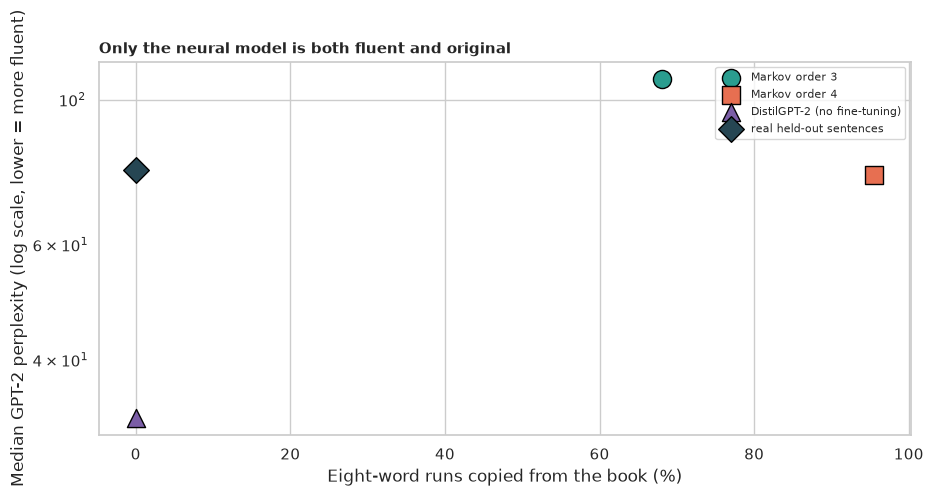

In [10]:
fig, ax = plt.subplots(figsize=(9.5, 4.8))
names = [
    "Markov order 3",
    "Markov order 4",
    "DistilGPT-2 (no fine-tuning)",
    "real held-out sentences",
]
for name, color, marker in zip(
    names, [TEAL, ORANGE, PURPLE, NAVY], ["o", "s", "^", "D"], strict=True
):
    ax.scatter(
        compare.loc[name, "mean copied 8-grams"] * 100,
        compare.loc[name, "median perplexity"],
        s=170,
        color=color,
        marker=marker,
        edgecolor="black",
        zorder=3,
        label=name,
    )
ax.set_yscale("log")
ax.set_xlabel("Eight-word runs copied from the book (%)")
ax.set_ylabel("Median GPT-2 perplexity (log scale, lower = more fluent)")
ax.set_title(
    "Only the neural model is both fluent and original", loc="left", fontweight="bold", fontsize=11
)
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(OUT_DIR / "03_markov_vs_neural.png", dpi=150)
plt.show()

**How to read this:**

- **The neural model is the most fluent and the most original:** median perplexity **32.6** (against 107.7 for the order-3 chain, 76.7 for order 4 and 78.0 for real Austen), and **0.0%** of its eight-word runs come from the book. Against the order-3 chain, Cliff's δ = **-0.55** (Mann-Whitney p = 3.2e-21). **We reject H₀.**
- **But its fluency is not Austen's:** **27.5%** of its words never occur in the book, and the example is a modern news-like sentence. It writes fluent English, not fluent *Austen*. Making it write in the book's style would need fine-tuning on the book, which we do not do here.
- **The comparison is unfair in an interesting way:** DistilGPT-2 has learned from vastly more text than the chains, and the same GPT-2 family is the judge, so a low perplexity partly means "sounds like itself". Still, it is the only source here that is fluent and not copied.

## 10. 🎯 Takeaways

1. **A Markov chain's memory trades originality for fluency.** At a memory of 1 word the chain copies **0.0%** of eight-word runs but is gibberish (GPT-2 perplexity 357); at 4 words it copies **95.5%** (and **78.5%** of its sentences are exact quotes) but reads like real English (perplexity 76.7, against 78.0 for real text).
2. **The legacy script's choice (memory 4) mostly quotes its training text.** Nobody noticed, because nothing was measured.
3. **More text helps, slowly:** ten times more text cut order-3 copying from 91.5% to 67.1%.
4. **A neural language model breaks the trade-off:** DistilGPT-2 is more fluent (perplexity 32.6) and copies 0.0%, though it writes modern English rather than the book's style.
5. **Always measure originality when you generate text:** a fluent output can simply be a quotation.

## 11. ⚠️ Limitations

- **One book, one author.** Austen's sentences are long and her vocabulary is small; a different corpus would shift every number, though not the direction of the trade-off.
- **Perplexity under one judge.** GPT-2 may have seen this book, and perplexity rewards plain, predictable text; it is a proxy for fluency, not a human rating.
- **A simple originality measure.** Eight-word runs catch copying but not close paraphrase.
- **200 sentences per source and one random seed;** the bootstrap intervals show the sampling noise but not the variation between seeds.
- **The neural sample is unconditioned** (prompt "The") and its first sentence is taken, so it is not matched to the chains' sentence length or style.
- **No human evaluation and no coherence beyond the sentence:** all the text here is judged one sentence at a time.